In [1]:
import os, time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve
)
from sklearn.manifold import TSNE

from transformers import BertTokenizer, BertModel
from google.colab import files

In [2]:
files.upload()
df = pd.read_excel("data_twitter_final.xlsx")

df = df[["normalisasi","label"]].dropna().drop_duplicates(subset=["normalisasi"])
df["label"] = df["label"].map({"Negatif":0,"Positif":1})
df = df[df["label"].isin([0,1])].reset_index(drop=True)

Saving data_twitter_final.xlsx to data_twitter_final.xlsx


In [3]:
class IndoBERTDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            padding="max_length",
            truncation=True,
            max_length=self.max_len,
            return_tensors="pt"
        )
        return enc["input_ids"].squeeze(0), enc["attention_mask"].squeeze(0), torch.tensor(self.labels[idx],dtype=torch.long)

    def __len__(self):
        return len(self.texts)

In [4]:
class IndoBERT_CNN(nn.Module):
    def __init__(self, bert):
        super().__init__()
        self.bert = bert
        for p in self.bert.parameters():
            p.requires_grad = False

        self.conv1 = nn.Conv1d(768,128,3,padding=1)
        self.conv2 = nn.Conv1d(768,128,5,padding=2)
        self.conv3 = nn.Conv1d(768,128,7,padding=3)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128*3,2)

    def extract_features(self, ids, mask):
        with torch.no_grad():
            x = self.bert(ids,mask).last_hidden_state
        x = x.permute(0,2,1)
        c1 = torch.max(self.relu(self.conv1(x)),dim=2)[0]
        c2 = torch.max(self.relu(self.conv2(x)),dim=2)[0]
        c3 = torch.max(self.relu(self.conv3(x)),dim=2)[0]
        return torch.cat([c1,c2,c3],1)

    def forward(self, ids, mask):
        x = self.extract_features(ids,mask)
        x = self.dropout(x)
        return self.fc(x)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["normalisasi"], df["label"], test_size=0.3, stratify=df["label"], random_state=42
)

In [6]:
tokenizer = BertTokenizer.from_pretrained("indobenchmark/indobert-base-p1")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
EPOCHS = 10
all_fold_losses = []

for tr_idx, val_idx in skf.split(X_train, y_train):

    bert = BertModel.from_pretrained("indobenchmark/indobert-base-p1").to(device)
    model = IndoBERT_CNN(bert).to(device)

    train_ds = IndoBERTDataset(X_train.iloc[tr_idx].tolist(), y_train.iloc[tr_idx].tolist(), tokenizer)
    val_ds   = IndoBERTDataset(X_train.iloc[val_idx].tolist(), y_train.iloc[val_idx].tolist(), tokenizer)

    train_loader = torch.utils.data.DataLoader(train_ds,8,shuffle=True)
    val_loader   = torch.utils.data.DataLoader(val_ds,8)

    optimizer = torch.optim.Adam(model.parameters(),lr=2e-4)
    criterion = nn.CrossEntropyLoss()

    fold_losses=[]

    for ep in range(EPOCHS):
        model.train()
        for ids,mask,labels in train_loader:
            ids,mask,labels = ids.to(device),mask.to(device),labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(ids,mask),labels)
            loss.backward()
            optimizer.step()

        model.eval()
        vloss=0
        with torch.no_grad():
            for ids,mask,labels in val_loader:
                ids,mask,labels = ids.to(device),mask.to(device),labels.to(device)
                vloss+=criterion(model(ids,mask),labels).item()

        fold_losses.append(vloss/len(val_loader))

    all_fold_losses.append(fold_losses)

best_epoch = np.argmin(np.mean(all_fold_losses,axis=0))+1
print("Epoch optimal:",best_epoch)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

Epoch optimal: 3


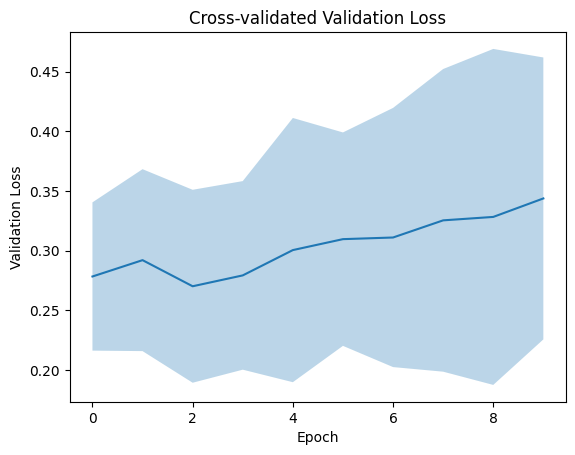

In [7]:
mean_val = np.mean(all_fold_losses,axis=0)
std_val  = np.std(all_fold_losses,axis=0)

plt.plot(mean_val)
plt.fill_between(range(EPOCHS), mean_val-std_val, mean_val+std_val, alpha=0.3)
plt.title("Cross-validated Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.show()

In [9]:
from sklearn.metrics import accuracy_score

bert = BertModel.from_pretrained("indobenchmark/indobert-base-p1").to(device)
final_model = IndoBERT_CNN(bert).to(device)

train_ds = IndoBERTDataset(X_train.tolist(), y_train.tolist(), tokenizer)
test_ds  = IndoBERTDataset(X_test.tolist(), y_test.tolist(), tokenizer)

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=8, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds, batch_size=8)

optimizer = torch.optim.Adam(final_model.parameters(), lr=2e-4)
criterion = nn.CrossEntropyLoss()

train_losses, train_accs = [], []

start_train = time.time()

for epoch in range(best_epoch):
    final_model.train()
    total_loss = 0
    y_true_epoch, y_pred_epoch = [], []

    for ids, mask, labels in train_loader:
        ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = final_model(ids, mask)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        y_pred_epoch.extend(torch.argmax(outputs, 1).cpu().numpy())
        y_true_epoch.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(train_loader)
    acc = accuracy_score(y_true_epoch, y_pred_epoch)

    train_losses.append(avg_loss)
    train_accs.append(acc)

    print(f"Epoch {epoch+1}/{best_epoch} | Loss={avg_loss:.4f} | Acc={acc:.4f}")

train_time = time.time() - start_train

Epoch 1/3 | Loss=0.3655 | Acc=0.8476
Epoch 2/3 | Loss=0.2220 | Acc=0.9133
Epoch 3/3 | Loss=0.1626 | Acc=0.9313


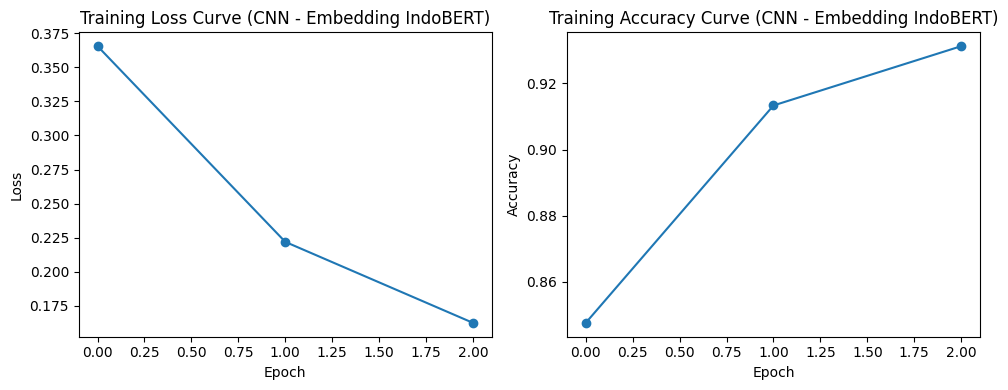

In [10]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(train_losses, marker='o')
plt.title("Training Loss Curve (CNN - Embedding IndoBERT)")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.plot(train_accs, marker='o')
plt.title("Training Accuracy Curve (CNN - Embedding IndoBERT)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       0.90      0.94      0.92       262
           1       0.90      0.84      0.87       169

    accuracy                           0.90       431
   macro avg       0.90      0.89      0.89       431
weighted avg       0.90      0.90      0.90       431



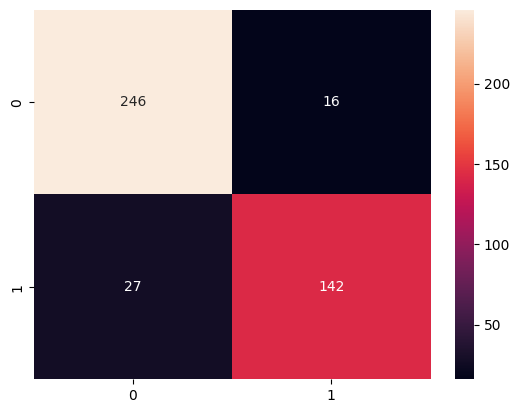

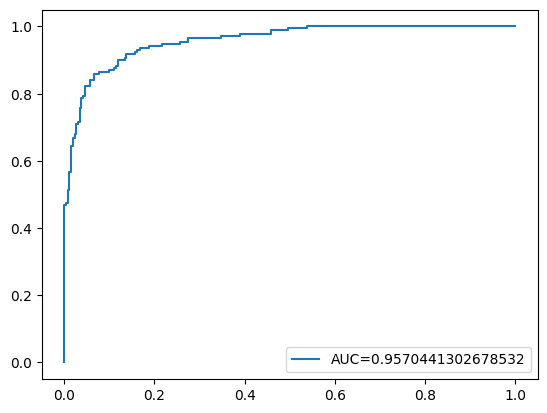

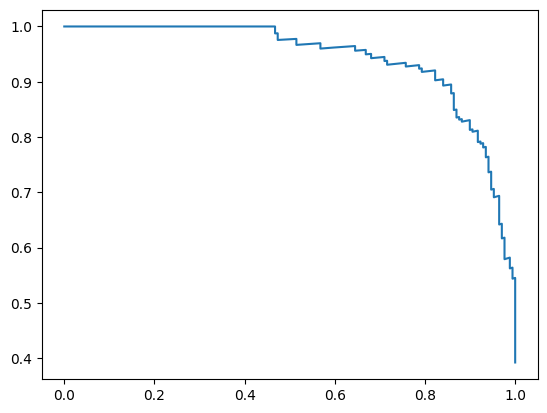

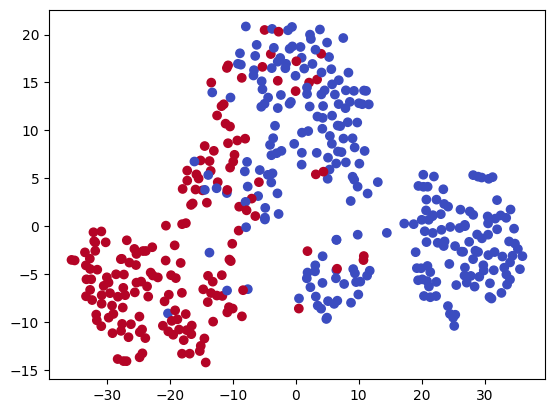

Training time (s): 24.29322624206543
Inference time (s): 3.300711154937744
Trainable parameters: 1475714


In [11]:
y_true,y_pred,y_prob=[],[],[]
start_inf=time.time()

final_model.eval()
with torch.no_grad():
    for ids,mask,labels in test_loader:
        ids,mask=ids.to(device),mask.to(device)
        out=final_model(ids,mask)
        prob=torch.softmax(out,1)[:,1]
        y_pred.extend(torch.argmax(out,1).cpu().numpy())
        y_true.extend(labels.numpy())
        y_prob.extend(prob.cpu().numpy())

infer_time=time.time()-start_inf

print(classification_report(y_true,y_pred))

cm=confusion_matrix(y_true,y_pred)
sns.heatmap(cm,annot=True,fmt="d")
plt.show()

fpr,tpr,_=roc_curve(y_true,y_prob)
plt.plot(fpr,tpr,label="AUC="+str(auc(fpr,tpr)))
plt.legend(); plt.show()

prec,rec,_=precision_recall_curve(y_true,y_prob)
plt.plot(rec,prec); plt.show()

features=[]
labels_tsne=[]

with torch.no_grad():
    for ids,mask,labels in test_loader:
        ids,mask=ids.to(device),mask.to(device)
        f=final_model.extract_features(ids,mask)
        features.append(f.cpu().numpy())
        labels_tsne.extend(labels.numpy())

X_tsne=TSNE(n_components=2).fit_transform(np.vstack(features))
plt.scatter(X_tsne[:,0],X_tsne[:,1],c=labels_tsne,cmap="coolwarm")
plt.show()

print("Training time (s):",train_time)
print("Inference time (s):",infer_time)
print("Trainable parameters:",sum(p.numel() for p in final_model.parameters() if p.requires_grad))